In [27]:
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
import numpy as np

In [28]:
a = tf.constant([10, 20, 30])
b = tf.constant([1, 2, 3])

print("Addition:", tf.add(a, b))
print("Subtraction:", tf.subtract(a, b))
print("Multiplication:", tf.multiply(a, b))
print("Division:", tf.divide(a, b))

Addition: tf.Tensor([11 22 33], shape=(3,), dtype=int32)
Subtraction: tf.Tensor([ 9 18 27], shape=(3,), dtype=int32)
Multiplication: tf.Tensor([10 40 90], shape=(3,), dtype=int32)
Division: tf.Tensor([10. 10. 10.], shape=(3,), dtype=float64)


In [29]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)


Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [30]:
x_train = np.asarray(x_train, dtype=np.float32)
x_train /= 255.0

x_test = np.asarray(x_test, dtype=np.float32)
x_test /= 255.0

In [31]:
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

model.summary()

C:\Users\ANIKET\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)                  │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
model.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [33]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8203 - loss: 0.7063 - val_accuracy: 0.9163 - val_loss: 0.3317
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9002 - loss: 0.3610 - val_accuracy: 0.9270 - val_loss: 0.2646
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9128 - loss: 0.3083 - val_accuracy: 0.9340 - val_loss: 0.2366
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9227 - loss: 0.2770 - val_accuracy: 0.9417 - val_loss: 0.2154
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9289 - loss: 0.2537 - val_accuracy: 0.9450 - val_loss: 0.2013
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9344 - loss: 0.2349 - val_accuracy: 0.9493 - val_loss: 0.1850
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 10s 3ms/step - accuracy: 0.9384 - loss: 0.2191 - val_accuracy: 0.9540 - val_loss: 0.1738
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 11s 3ms/step - accuracy: 0.9427 - loss: 0.205

In [34]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)

print("Test Accuracy:", test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9510 - loss: 0.1732
Test Accuracy: 95.09999752044678 %


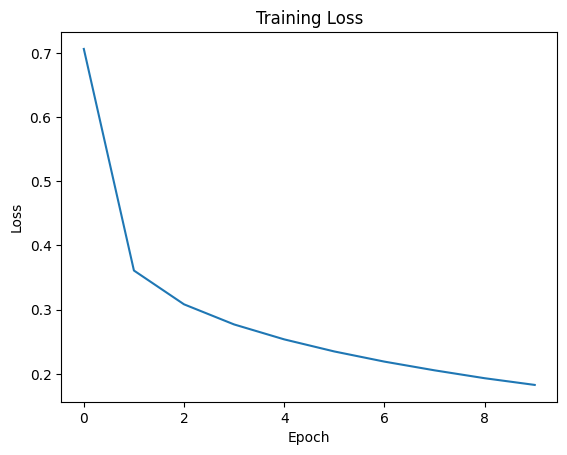

In [35]:
plt.plot(history.history['loss'])
plt.title('Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.show()

In [36]:
predictions = model.predict(x_test[:5])

for i in range(5):
    print("Actual:", y_test[i])
    print("Predicted:", np.argmax(predictions[i]))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
Actual: 7
Predicted: 7
Actual: 2
Predicted: 2
Actual: 1
Predicted: 1
Actual: 0
Predicted: 0
Actual: 4
Predicted: 4


In [37]:
import torch
import torch.nn as nn
import torch.optim as optim

In [38]:
a = torch.tensor([10.0, 20.0, 30.0])
b = torch.tensor([1.0, 2.0, 3.0])

print("Addition:", a + b)
print("Subtraction:", a - b)
print("Multiplication:", a * b)
print("Division:", a / b)

Addition: tensor([11., 22., 33.])
Subtraction: tensor([ 9., 18., 27.])
Multiplication: tensor([10., 40., 90.])
Division: tensor([10., 10., 10.])


In [39]:
matrix = torch.randn(2, 2)

print("Matrix:")
print(matrix)

print("Transpose:")
print(matrix.T)

Matrix:
tensor([[ 0.6258,  0.2010],
        [ 2.9017, -1.6692]])
Transpose:
tensor([[ 0.6258,  2.9017],
        [ 0.2010, -1.6692]])


In [40]:
x = torch.tensor(2.0, requires_grad=True)

y = x ** 2

y.backward()

print("Gradient:", x.grad)

Gradient: tensor(4.)


In [41]:
model = nn.Linear(2, 1)

optimizer = optim.SGD(model.parameters(), lr=0.01)

input_data = torch.tensor([[1.0, 2.0]])

output = model(input_data)

loss = output.sum()

loss.backward()

optimizer.step()

print("Neural Network Output:", output)

Neural Network Output: tensor([[-0.5684]], grad_fn=<AddmmBackward0>)


In [24]:
pip install theano

Defaulting to user installation because normal site-packages is not writeable
     ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
     ---------------------------------------- 2.8/2.8 MB 21.8 MB/s  0:00:00
  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'error'
Note: you may need to restart the kernel to use updated packages.


  error: subprocess-exited-with-error
  
  python setup.py egg_info did not run successfully.
  exit code: 1
  
  [22 lines of output]
  C:\Users\ANIKET\AppData\Local\Temp\pip-install-cs9qmzba\theano_086738e4f0764de39c1b358641caf0ce\versioneer.py:564: SyntaxWarning: invalid escape sequence '\s'
    mo = re.search(r'=\s*"(.*)"', line)
  Traceback (most recent call last):
    File "<string>", line 2, in <module>
      exec(compile('''
      ~~~~^^^^^^^^^^^^
      # This is <pip-setuptools-caller> -- a caller that pip uses to run setup.py
      ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
      ...<32 lines>...
      exec(compile(setup_py_code, filename, "exec"))
      ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
      ''' % ('C:\\Users\\ANIKET\\AppData\\Local\\Temp\\pip-install-cs9qmzba\\theano_086738e4f0764de39c1b358641caf0ce\\setup.py',), "<pip-setuptools-caller>", "exec"))
      ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

In [26]:
import sys
print(sys.version)


3.13.5 (tags/v3.13.5:6cb20a2, Jun 11 2025, 16:15:46) [MSC v.1943 64 bit (AMD64)]


In [25]:
import theano
import theano.tensor as T

ModuleNotFoundError: No module named 'theano'

In [ ]:
x = T.dscalar('x')
y = T.dscalar('y')

z = x ** 2 + y ** 2

In [ ]:
dx = T.grad(z, x)
dy = T.grad(z, y)

In [ ]:
calculate = theano.function([x, y], [z, dx, dy])

result = calculate(3, 4)

print("Expression:", result[0])
print("Derivative w.r.t x:", result[1])
print("Derivative w.r.t y:", result[2])